Считайте датасет из файла train.csv (это данные о выживаемости на Титанике) - 1 балл

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [ ]:
df = pd.read_csv('train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Визуализируйте распределение значений признаков Survived, Pclass, Age, Sex. Parch - 2 балла

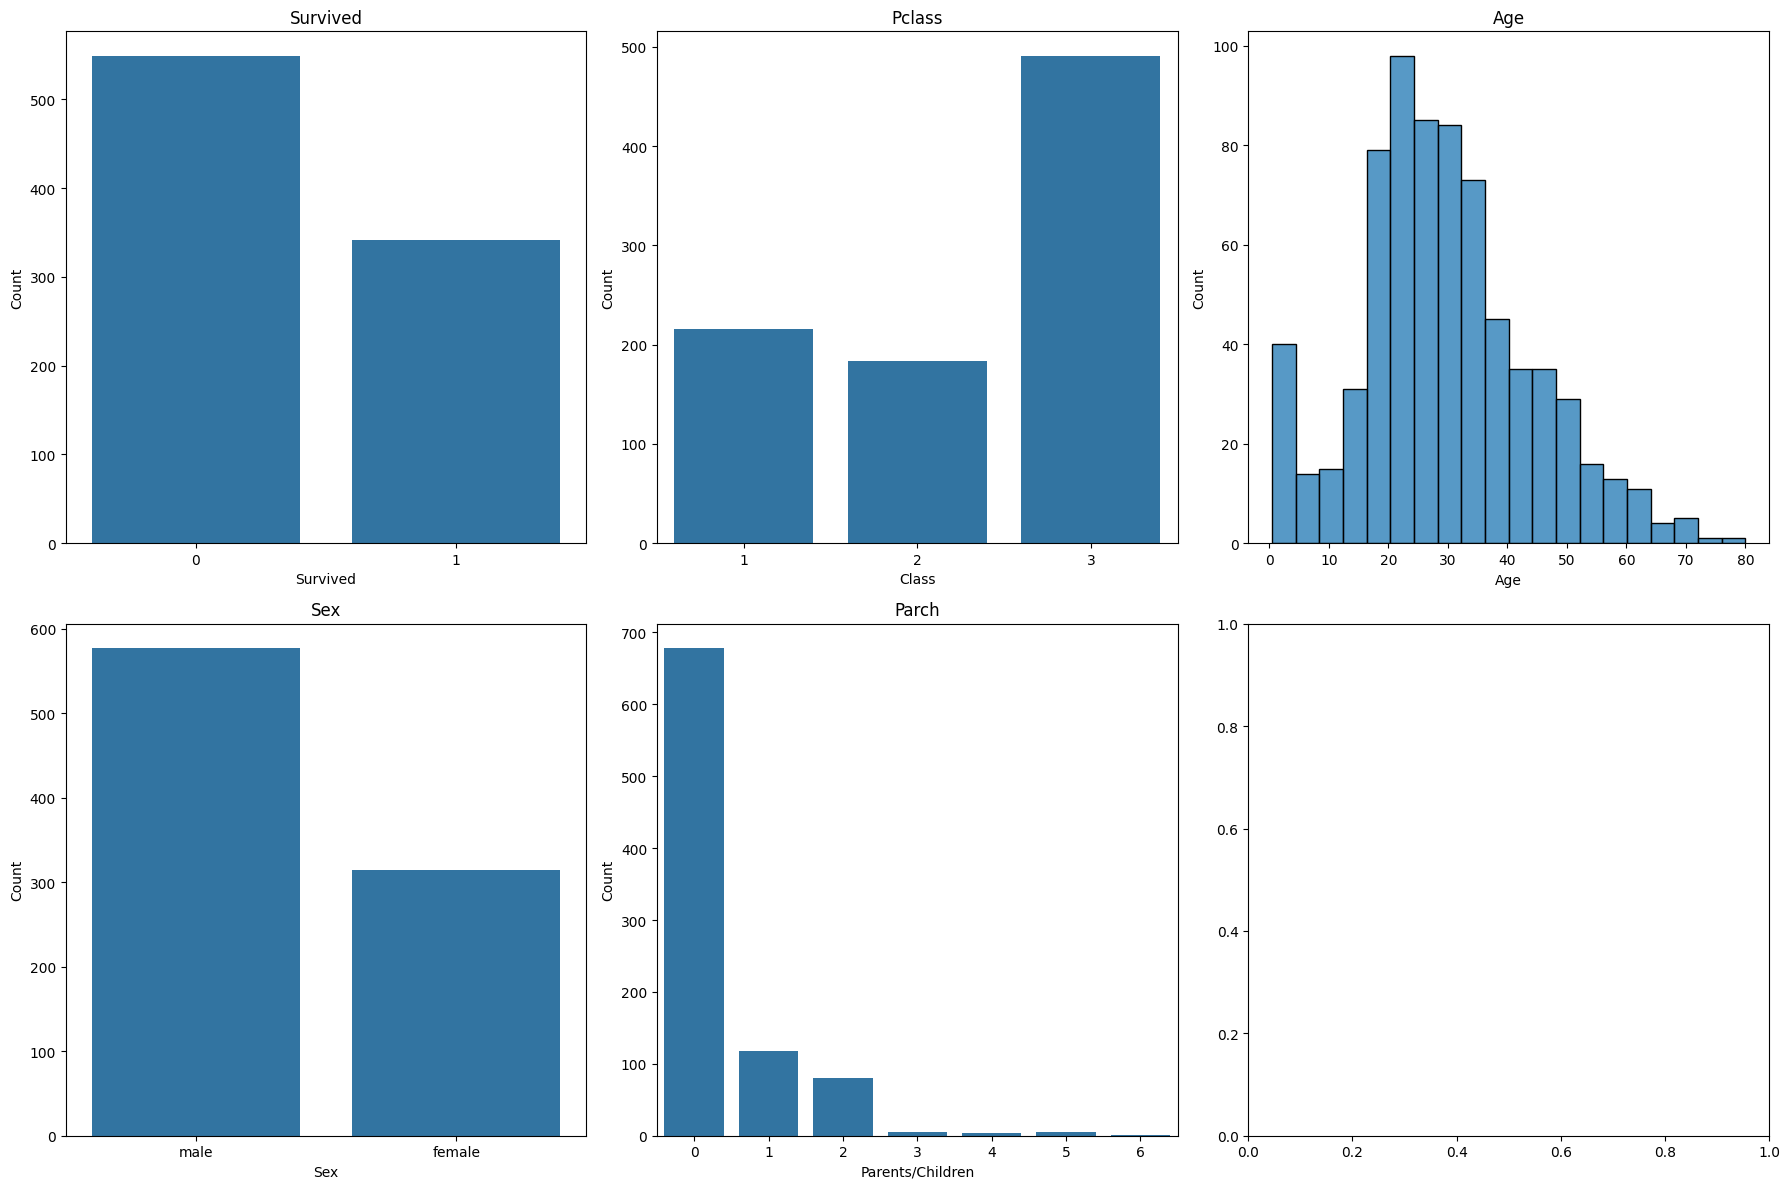

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(18, 12))
sns.countplot(data=df, x='Survived', ax=axs[0, 0]).set(title='Survived', xlabel='Survived', ylabel='Count')
sns.countplot(data=df, x='Pclass', ax=axs[0, 1]).set(title='Pclass', xlabel='Class', ylabel='Count')
sns.histplot(df['Age'], kde=False, ax=axs[0, 2]).set(title='Age', xlabel='Age', ylabel='Count')
sns.countplot(data=df, x='Sex', ax=axs[1, 0]).set(title='Sex', xlabel='Sex', ylabel='Count')
sns.countplot(data=df, x='Parch', ax=axs[1, 1]).set(title='Parch', xlabel='Parents/Children', ylabel='Count')
plt.tight_layout()

Постройте график типа boxplot для столбца Age - 1 балл

Text(0.5, 1.0, 'Boxplot of Age')

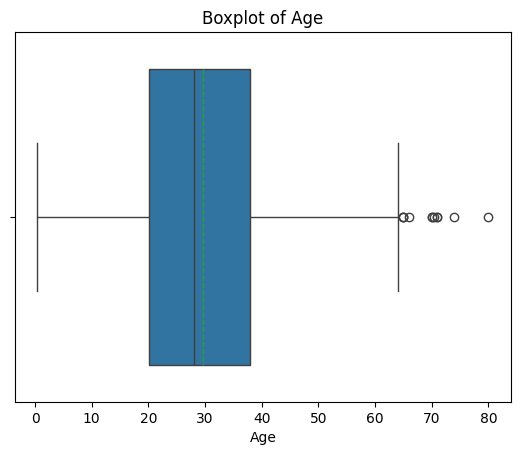

In [ ]:
sns.boxplot(x=df['Age'], meanline=True, showmeans=True)
plt.title('Boxplot of Age')

Проинтепретируйте полученный график - 1 балл


Медиана составляет примерно 28 лет, указывая на то, что половина пассажиров младше этого возраста. Межквартильный интервал (IQR) от 21 до 37 лет охватывает 50% пассажиров. Горизонтальные линии показали диапазон возрастов от 0 до 65 лет, а отдельные точки справа (выбросы) указывают на пожилых пассажиров старше 65 лет.

Постройте график типа pie chart для переменных Survived, Pclass, подпишите доли в процентах - 1 балл

<Axes: title={'center': 'Pclass (%)'}, ylabel='count'>

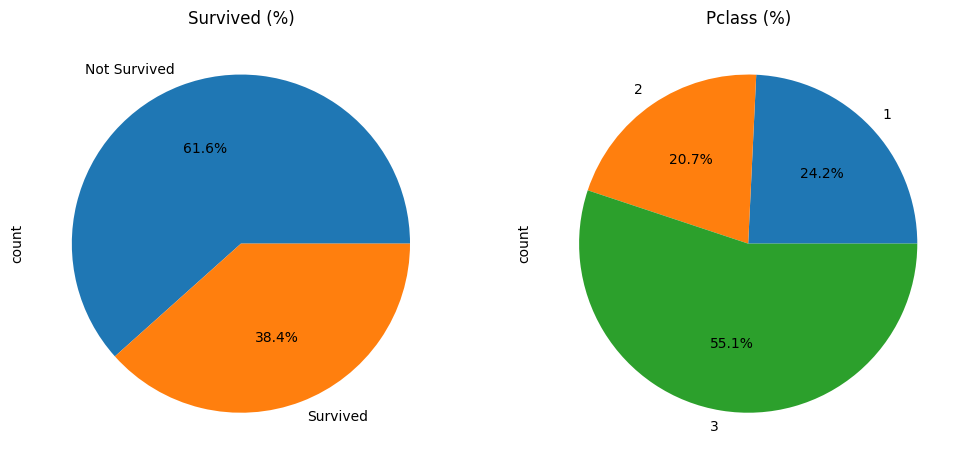

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(12,6))
ax1, ax2 = axes
r1=df['Survived'].value_counts().sort_index()
labels = ['Survived' if x == 1 else 'Not Survived' for x in r1.index]
r1.plot(kind='pie', labels=labels, autopct='%1.1f%%', ax=ax1, title='Survived (%)')
r2=df['Pclass'].value_counts().sort_index()
r2.plot(kind='pie', autopct='%1.1f%%', ax=ax2, title='Pclass (%)')

Постройте график типа pairplot для всех числовых переменных датасета - 1 балл

Text(0.5, 1.02, 'Pairplot of Num')

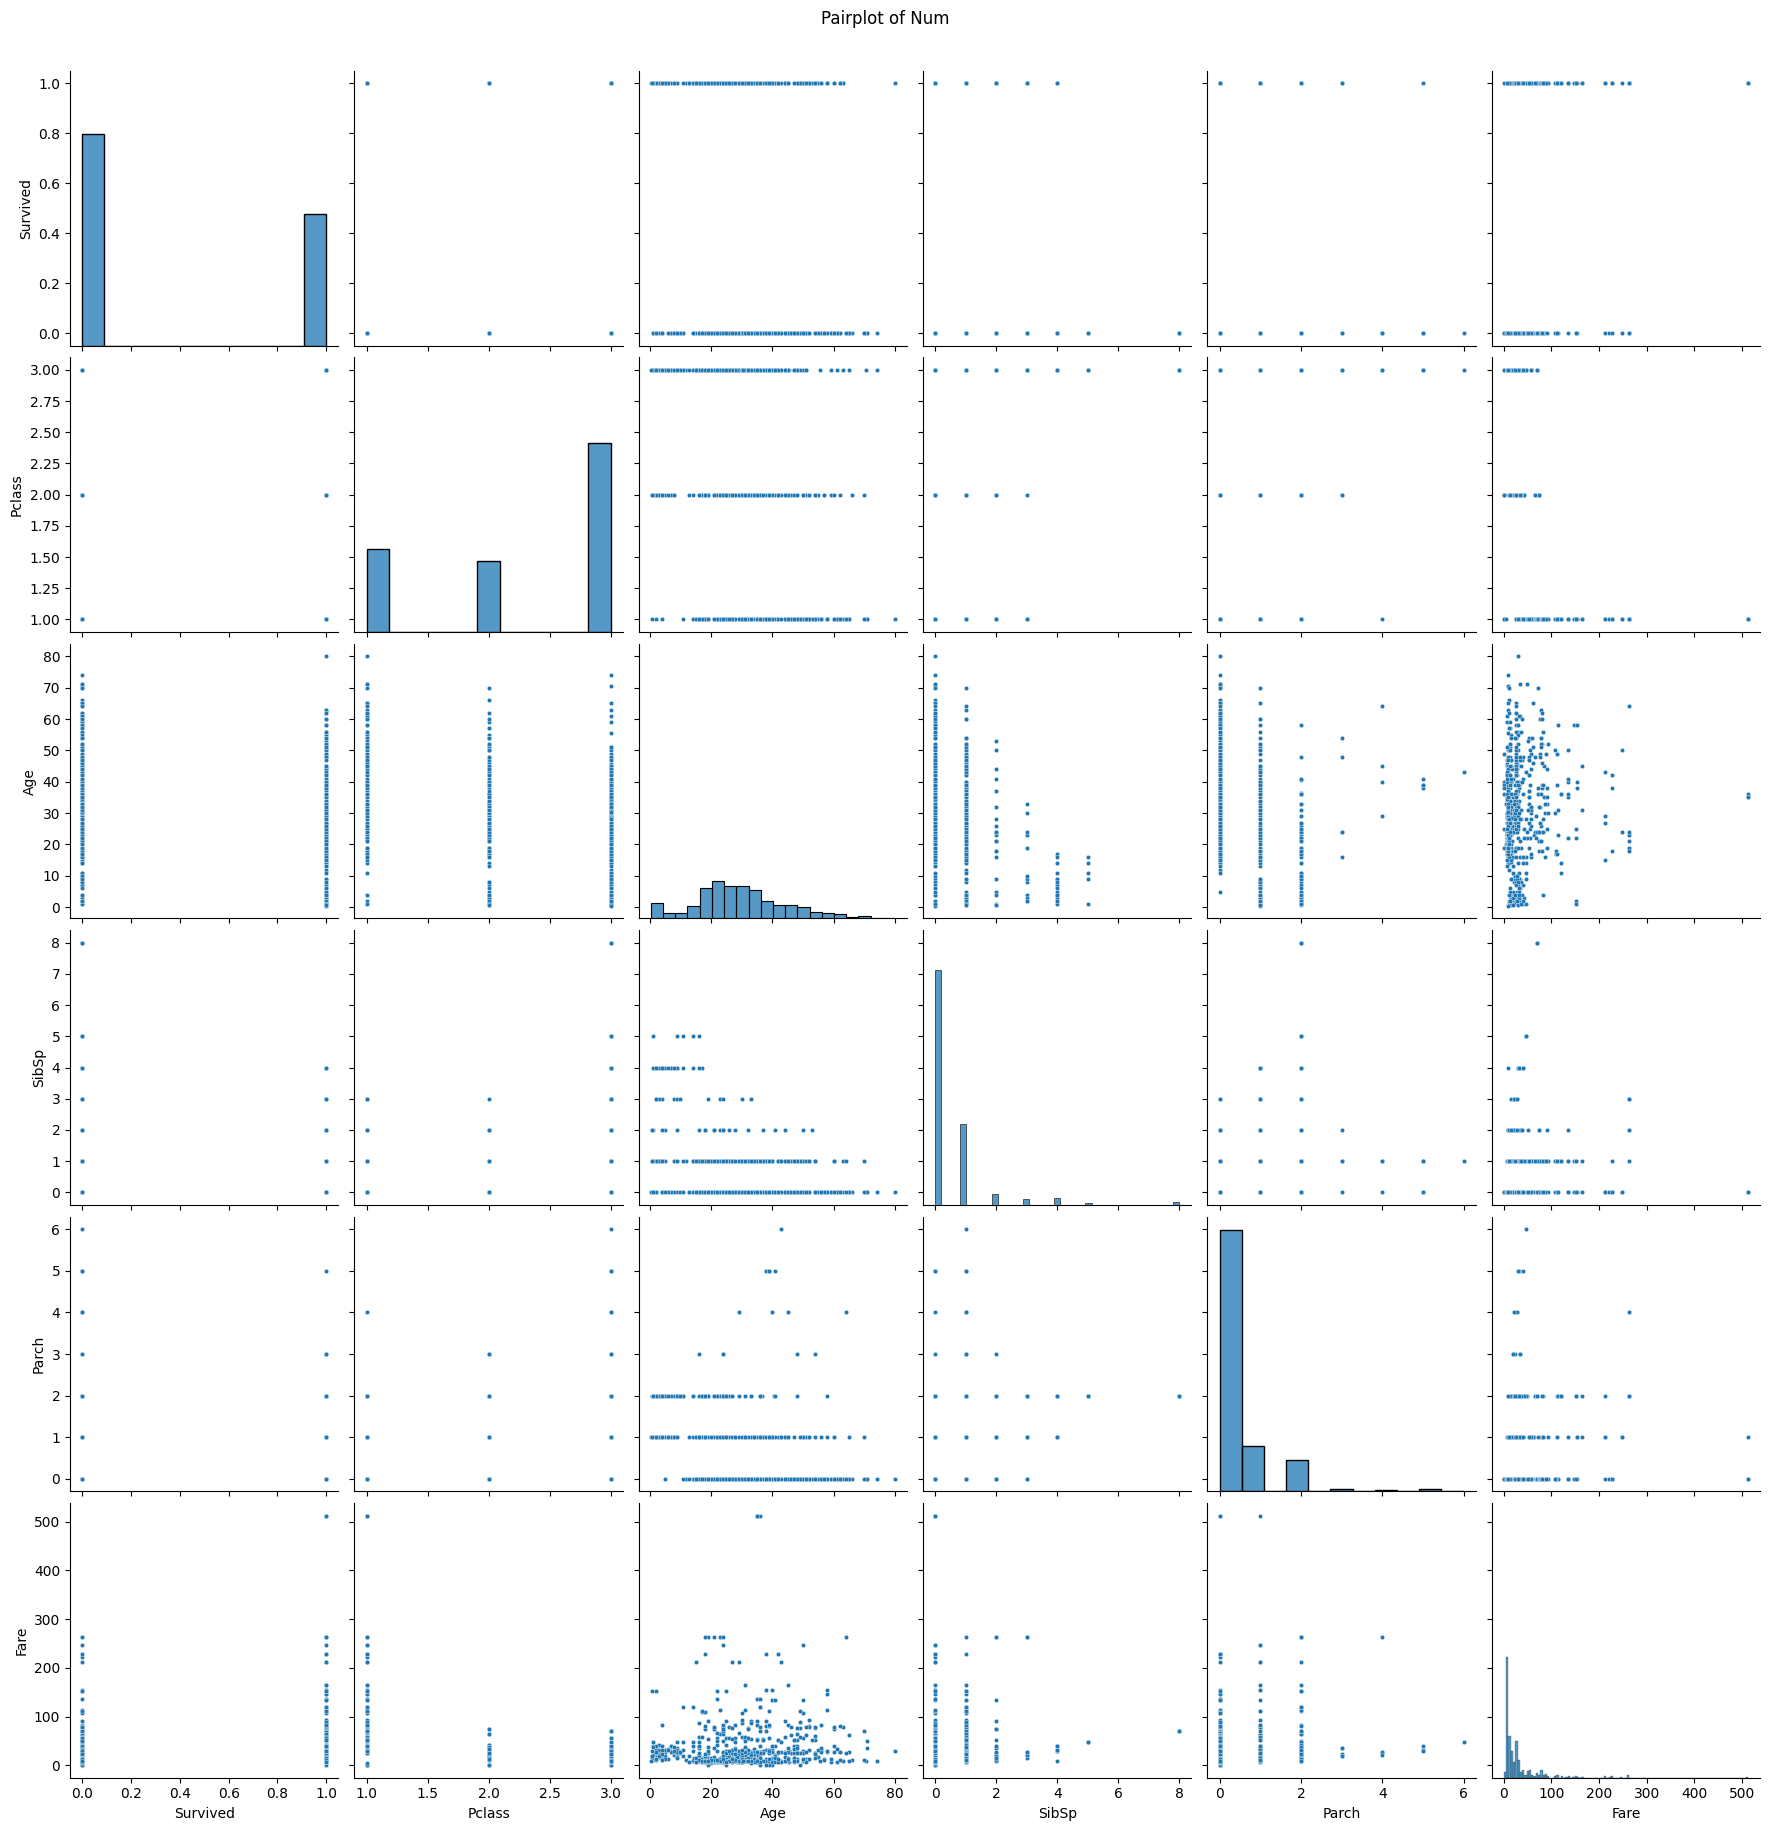

In [ ]:
sns.pairplot(df.select_dtypes(include='number').drop('PassengerId', axis=1), height=3, plot_kws={'s': 10})
plt.suptitle('Pairplot of Num', y=1.02)

Постройте интерактивный sunburst plot (визуализация иерархических данных) с помощью plotly. На первом уровне иерархии - количество пассажиров в каждом из классов, а на втором количество женщин/мужчин в этом классе - 2 балла

In [ ]:
fig = px.sunburst(df,
                  path=['Pclass', 'Sex'],
                  title='Sunburst plot of PClass/Sex')
fig.show()